# Predicting Residential Property Sale Prices in New York City (2025)
**Module:** 6COSC017C Machine Learning and Data Analytics — CW1

**Business question:** Can we predict the sale price of a residential property in New York City from its physical characteristics, location and sale timing — and which factors drive price the most?

**Dataset:** NYC Department of Finance — Annualized Property Sales, calendar year 2025 (five borough files).
Source: https://www.nyc.gov/site/finance/property/property-annualized-sales-update.page (public NYC government data).

**Notebook structure**
1. Load data (combine 5 borough files)
2. First look at the data
3. Exploratory Data Analysis
4. Data preparation *(next)*
5. Model training *(next)*
6. Model evaluation *(next)*

## 0. Setup — libraries

In [1]:
# Core data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings so wide tables are readable
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

# Fixed random seed so every result in this notebook is reproducible
RANDOM_STATE = 42

## 1. Load data

The Department of Finance publishes one Excel file per borough. Each file has **6 title/note lines** at the top, then the column headers on line 7, followed by one empty row.
We therefore:
1. read each file with `header=6` (0-based row index of the header line),
2. drop fully empty rows,
3. add a `borough_name` column so we keep track of where each row came from,
4. stack (concatenate) the five files into one DataFrame — they share exactly the same 21 columns, so a vertical concatenation is the correct way to combine them.

In [2]:
# File name -> readable borough name
BOROUGH_FILES = {
    "2025_manhattan.xlsx":     "Manhattan",
    "2025_bronx.xlsx":         "Bronx",
    "2025_brooklyn.xlsx":      "Brooklyn",
    "2025_queens.xlsx":        "Queens",
    "2025_staten_island.xlsx": "Staten Island",
}

frames = []
for file_name, borough in BOROUGH_FILES.items():
    df_b = pd.read_excel(file_name, header=6)   # header is on the 7th line
    df_b = df_b.dropna(how="all")               # remove empty spacer rows
    df_b["borough_name"] = borough              # remember the source file
    frames.append(df_b)
    print(f"{borough:<14} {len(df_b):>7,} rows")

df_raw = pd.concat(frames, ignore_index=True)
print(f"\nCombined dataset: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

Manhattan       19,724 rows


Bronx            6,818 rows


Brooklyn        23,472 rows


Queens          27,258 rows


Staten Island    7,796 rows

Combined dataset: 85,068 rows x 22 columns


### 1.1 Clean column names
The original headers contain line breaks, double spaces and capital letters (e.g. `'GROSS \nSQUARE FEET'`). We convert them to `snake_case` so they are easy to use in code.

In [3]:
def clean_col(name: str) -> str:
    name = " ".join(str(name).split())          # remove line breaks / extra spaces
    return name.lower().replace("-", "").replace(" ", "_")

df_raw.columns = [clean_col(c) for c in df_raw.columns]
df_raw.columns.tolist()

['borough',
 'neighborhood',
 'building_class_category',
 'tax_class_at_present',
 'block',
 'lot',
 'easement',
 'building_class_at_present',
 'address',
 'apartment_number',
 'zip_code',
 'residential_units',
 'commercial_units',
 'total_units',
 'land_square_feet',
 'gross_square_feet',
 'year_built',
 'tax_class_at_time_of_sale',
 'building_class_at_time_of_sale',
 'sale_price',
 'sale_date',
 'borough_name']

### 1.2 Sanity checks after loading
We confirm that every borough loaded, that the sale dates cover the full 2025 calendar year, and that the combination produced no duplicate rows.

In [4]:
print("Rows per borough:")
print(df_raw["borough_name"].value_counts(), "\n")

print("Sale date range:", df_raw["sale_date"].min().date(), "to", df_raw["sale_date"].max().date())
print("Exact duplicate rows:", df_raw.duplicated().sum())

Rows per borough:
borough_name
Queens           27258
Brooklyn         23472
Manhattan        19724
Staten Island     7796
Bronx             6818
Name: count, dtype: int64 

Sale date range: 2025-01-01 to 2025-12-31
Exact duplicate rows: 0


## 2. First look at the data

In [5]:
df_raw.head()

,borough,neighborhood,building_class_category,tax_class_at_present,block,lot,easement,building_class_at_present,address,apartment_number,zip_code,residential_units,commercial_units,total_units,land_square_feet,gross_square_feet,year_built,tax_class_at_time_of_sale,building_class_at_time_of_sale,sale_price,sale_date,borough_name
0,1.00,ALPHABET CITY,01 ONE FAMILY DWELLINGS,1,376.00,43.00,NaN,S1,743 EAST 6 STREET,NaN,"10,009.00",1.00,1.00,2.00,"2,090.00","3,680.00","1,940.00",1.00,S1,0.00,2025-01-23,Manhattan
1,1.00,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372.00,9.00,NaN,C7,272 EAST 3 STREET,NaN,"10,009.00",8.00,1.00,9.00,"2,021.00","7,129.00","1,900.00",2.00,C7,0.00,2025-12-15,Manhattan
2,1.00,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372.00,19.00,NaN,C7,"292 EAST 3 STREET, 4B",NaN,"10,009.00",9.00,1.00,10.00,"2,401.00","6,920.00","1,920.00",2.00,C7,0.00,2025-02-07,Manhattan
3,1.00,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,376.00,41.00,NaN,C6,"745 EAST 6TH STREET, 1B",NaN,"10,009.00",28.00,0.00,28.00,"4,542.00","18,254.00","1,900.00",2.00,C4,"540,000.00",2025-12-17,Manhattan
4,1.00,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,385.00,38.00,NaN,C6,"21-23 AVENUE C, 5B",NaN,"10,009.00",20.00,2.00,22.00,"3,315.00","17,160.00","1,900.00",2.00,C4,0.00,2025-11-11,Manhattan


### 2.1 Data types
`info()` shows each column's type and how many non-missing values it has. This tells us which columns are numeric (usable directly in models) and which are text/categorical (need encoding later).

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85068 entries, 0 to 85067
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   borough                         85068 non-null  float64       
 1   neighborhood                    85068 non-null  object        
 2   building_class_category         85068 non-null  object        
 3   tax_class_at_present            85068 non-null  object        
 4   block                           85068 non-null  float64       
 5   lot                             85068 non-null  float64       
 6   easement                        0 non-null      float64       
 7   building_class_at_present       85068 non-null  object        
 8   address                         85068 non-null  object        
 9   apartment_number                20679 non-null  object        
 10  zip_code                        85049 non-null  float64       
 11  re

### 2.2 Missing values
Missing values must be identified before modelling, because most scikit-learn models cannot handle them. We show the count and percentage per column.

In [7]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct":   (df_raw.isna().mean() * 100).round(1),
}).sort_values("missing_pct", ascending=False)
missing[missing["missing_count"] > 0]

,missing_count,missing_pct
easement,85068,100.00
apartment_number,64389,75.70
gross_square_feet,38358,45.10
land_square_feet,38360,45.10
commercial_units,35207,41.40
residential_units,20663,24.30
total_units,17510,20.60
year_built,5562,6.50
zip_code,19,0.00


**Observations**
- `easement` is 100% empty → it carries no information and will be dropped.
- `apartment_number` is mostly empty because it only applies to individual apartment units.
- `land_square_feet` and `gross_square_feet` are missing for many rows. In this dataset, co-op and condo sales are recorded **per apartment unit**, so building size is not recorded for them. This drives our scope decision in the Data Preparation section.

### 2.3 The target variable: `sale_price`
Not every record is a real market sale. Transfers between family members, or deeds transferred for legal reasons, are recorded with a price of **$0** or a token amount. These are not market prices and would mislead a price model.

In [8]:
price = df_raw["sale_price"]
print(f"Sales recorded at $0:        {(price == 0).sum():>7,}")
print(f"Sales below $10,000:         {(price < 10_000).sum():>7,}")
print(f"Sales of $10,000 or more:    {(price >= 10_000).sum():>7,}")
print()
price[price >= 10_000].describe()

Sales recorded at $0:         29,608
Sales below $10,000:          31,436
Sales of $10,000 or more:     53,632



count          53,632.00
mean        3,265,885.50
std        18,620,058.12
min            10,000.00
25%           560,000.00
50%           885,000.00
75%         1,550,000.00
max     1,080,000,000.00
Name: sale_price, dtype: float64

**Observation:** among real sales, the median price is far below the mean and the maximum is over $1 billion → the target is **heavily right-skewed**. We will look at this in the EDA and consider a log transformation.

### 2.4 Building class categories
The dataset mixes very different property types (houses, apartments, offices, garages, vacant land). Predicting one price for all of them would not be meaningful, so we look at what is there.

In [9]:
df_raw["building_class_category"].value_counts().head(15)

building_class_category
01 ONE FAMILY DWELLINGS              18578
02 TWO FAMILY DWELLINGS              15732
10 COOPS - ELEVATOR APARTMENTS       13620
13 CONDOS - ELEVATOR APARTMENTS      13464
03 THREE FAMILY DWELLINGS             4522
07 RENTALS - WALKUP APARTMENTS        2880
09 COOPS - WALKUP APARTMENTS          2448
04 TAX CLASS 1 CONDOS                 1620
15 CONDOS - 2-10 UNIT RESIDENTIAL     1507
44 CONDO PARKING                      1434
17 CONDO COOPS                        1304
12 CONDOS - WALKUP APARTMENTS         1000
05 TAX CLASS 1 VACANT LAND             965
22 STORE BUILDINGS                     825
29 COMMERCIAL GARAGES                  598
Name: count, dtype: int64

**Observation:** the three most common categories are 1-family, 2-family and 3-family homes. For these, building size, land size and year built are recorded, which makes them the best-suited group for a price-prediction model.

---
## 3. Exploratory Data Analysis (EDA)

### 3.0 Analysis population
Based on Section 2, the EDA focuses on the population the model will actually be used for:

| Filter | Reason |
|---|---|
| Building class category **01, 02, 03** (1-, 2- and 3-family homes) | Most common residential type; building size, land size and year built are recorded for them (unlike co-ops/condos, which are recorded per unit). Mixing houses with offices, garages or vacant land would make a single price model meaningless. |
| `sale_price >= $10,000` | Removes $0 and token transfers (family transfers, legal deed changes) that are not market prices. |

We keep this as a *copy* (`df_res`) so the raw data stays untouched. Remaining data-quality problems (missing sizes, impossible values, package sales) are only **identified** here and **fixed** in Section 4.

In [10]:
RESIDENTIAL_CATEGORIES = [
    "01 ONE FAMILY DWELLINGS",
    "02 TWO FAMILY DWELLINGS",
    "03 THREE FAMILY DWELLINGS",
]
MIN_MARKET_PRICE = 10_000

is_residential = df_raw["building_class_category"].isin(RESIDENTIAL_CATEGORIES)
is_market_sale = df_raw["sale_price"] >= MIN_MARKET_PRICE

df_res = df_raw[is_residential & is_market_sale].copy()

# Short labels make the charts easier to read
df_res["home_type"] = df_res["building_class_category"].map({
    "01 ONE FAMILY DWELLINGS":   "1-family",
    "02 TWO FAMILY DWELLINGS":   "2-family",
    "03 THREE FAMILY DWELLINGS": "3-family",
})

print(f"All records:                    {len(df_raw):>7,}")
print(f"1-3 family homes:               {is_residential.sum():>7,}")
print(f"1-3 family market sales (kept): {len(df_res):>7,}")
print(f"Share of 1-3 family records that are non-market transfers: "
      f"{1 - len(df_res) / is_residential.sum():.1%}")

All records:                     85,068
1-3 family homes:                38,832
1-3 family market sales (kept):  19,645
Share of 1-3 family records that are non-market transfers: 49.4%


### 3.1 Shape and variable types
Knowing which variables are numeric, categorical or dates decides how each one is explored and, later, how it is encoded.

In [11]:
print("Shape of the analysis population:", df_res.shape)

numeric_cols = ["sale_price", "gross_square_feet", "land_square_feet", "year_built",
                "residential_units", "commercial_units", "total_units"]
categorical_cols = ["borough_name", "neighborhood", "home_type", "zip_code",
                    "building_class_at_time_of_sale", "tax_class_at_time_of_sale"]

pd.DataFrame({
    "type": ["numeric"] * len(numeric_cols) + ["categorical"] * len(categorical_cols) + ["date"],
    "column": numeric_cols + categorical_cols + ["sale_date"],
})

Shape of the analysis population: (19645, 23)


,type,column
0,numeric,sale_price
1,numeric,gross_square_feet
2,numeric,land_square_feet
3,numeric,year_built
4,numeric,residential_units
5,numeric,commercial_units
6,numeric,total_units
7,categorical,borough_name
8,categorical,neighborhood
9,categorical,home_type


### 3.2 Summary statistics — numeric variables
Measures of central tendency (mean, median) and spread (variance, standard deviation) describe the typical property and how much properties differ. **Skewness** and **kurtosis** tell us whether the distributions are symmetric and heavy-tailed, which matters for models that assume roughly normal errors (e.g. linear regression).

In [12]:
num = df_res[numeric_cols]

summary = pd.DataFrame({
    "count":    num.count(),
    "mean":     num.mean(),
    "median":   num.median(),
    "variance": num.var(),
    "std":      num.std(),
    "min":      num.min(),
    "max":      num.max(),
    "skewness": num.skew(),
    "kurtosis": num.kurt(),
})
summary

,count,mean,median,variance,std,min,max,skewness,kurtosis
sale_price,19645,"1,149,331.46","895,000.00","1,563,679,250,827.86","1,250,471.61","10,000.00","46,000,000.00",11.19,234.49
gross_square_feet,19569,"1,992.23","1,800.00","917,197.96",957.70,0.00,"43,504.00",6.32,197.23
land_square_feet,19569,"3,102.42","2,500.00","4,825,152.91","2,196.62",297.00,"88,945.00",9.65,225.48
year_built,19634,"1,942.35","1,935.00",948.63,30.80,"1,826.00","2,025.00",0.79,-0.00
residential_units,19569,1.59,1.00,0.74,0.86,0.00,73.00,29.99,"2,445.64"
commercial_units,19569,0.03,0.00,0.03,0.17,0.00,3.00,5.98,37.51
total_units,19569,1.62,1.00,0.78,0.89,0.00,75.00,29.61,"2,407.17"


In [13]:
# Percentiles of the target give a feel for the price range of a "typical" home
df_res["sale_price"].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).to_frame("sale_price")

,sale_price
0.01,"150,000.00"
0.05,"400,000.00"
0.25,"686,000.00"
0.50,"895,000.00"
0.75,"1,250,000.00"
0.95,"2,500,000.00"
0.99,"5,850,000.00"


**Observations**
- The **median sale price is about \$895k, but the mean is about \$1.15M**. When the mean is well above the median, a small number of very expensive homes pull the average up. With a skewness of about 11, `sale_price` is strongly right-skewed.
- `gross_square_feet`, `land_square_feet` and the unit counts are also strongly right-skewed (skewness 6–30), with a few very large properties.
- `residential_units` has a **maximum of 73**, which is impossible for a 1–3 family home. This is a data error and will be corrected in Section 4.
- `year_built` is roughly symmetric (skewness about 0.8). Most homes were built in the first half of the 20th century (median around 1930–1940).
- `commercial_units` is 0 for about 97% of homes, so on its own it carries very little information.

### 3.3 Summary statistics — categorical variables
For categorical variables, mean and variance do not apply; instead we look at the number of distinct values (cardinality) and the most frequent value. High cardinality affects the encoding choice in Section 4.

In [14]:
df_res[categorical_cols].astype(str).describe().T

,count,unique,top,freq
borough_name,19645,5,Queens,7918
neighborhood,19645,229,FLUSHING-NORTH,583
home_type,19645,3,1-family,10196
zip_code,19645,163,10314.0,665
building_class_at_time_of_sale,19645,18,A1,3779
tax_class_at_time_of_sale,19645,1,1.0,19645


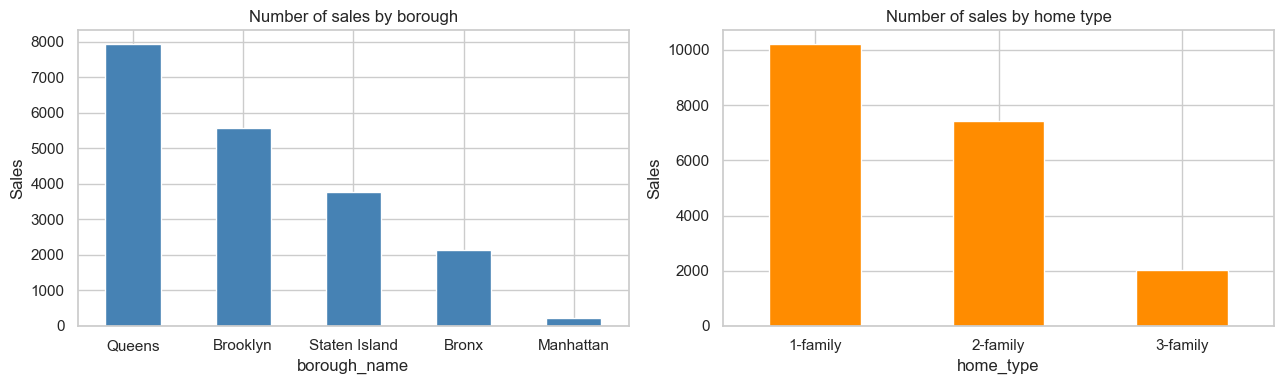

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df_res["borough_name"].value_counts().plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Number of sales by borough")
axes[0].set_ylabel("Sales")
axes[0].tick_params(axis="x", rotation=0)

df_res["home_type"].value_counts().sort_index().plot.bar(ax=axes[1], color="darkorange")
axes[1].set_title("Number of sales by home type")
axes[1].set_ylabel("Sales")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Observations**
- Queens and Brooklyn account for most sales; **Manhattan has only about 240 house sales**, because Manhattan housing is mostly apartments. A model will have little data to learn Manhattan prices from, so we should check its error per borough.
- `neighborhood` (about 230 values) and `zip_code` (about 160 values) have **high cardinality**. One-hot encoding all of them would create hundreds of sparse columns, so a different approach (e.g. target encoding or grouping) is considered in Section 4.
- `tax_class_at_time_of_sale` has a single value (class 1) for every row, so it carries **no information** and will be dropped.

### 3.4 Distribution of the target variable
The shape of the target decides whether we model the price directly or a transformation of it. A strongly skewed target makes squared-error models focus on the few most expensive homes.

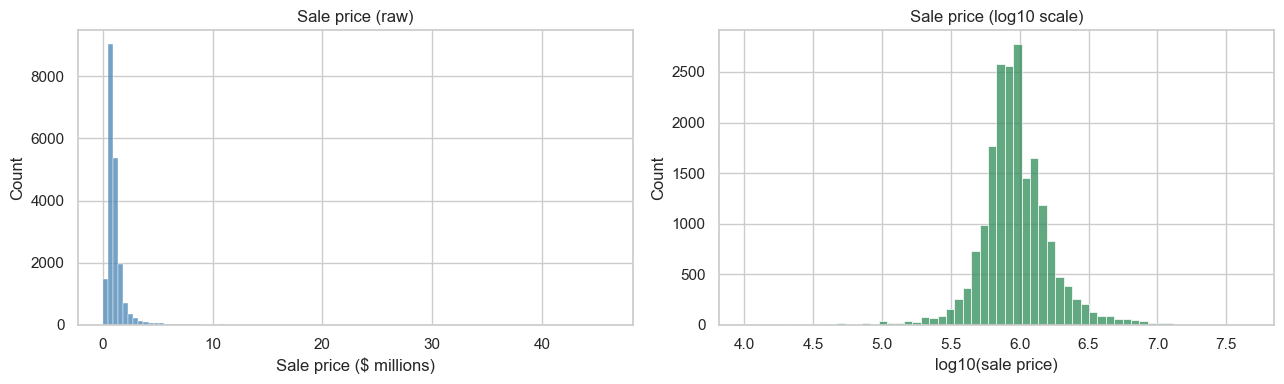

Skewness raw: 11.19   |   Skewness log: -0.27


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_res["sale_price"] / 1e6, bins=100, ax=axes[0], color="steelblue")
axes[0].set_title("Sale price (raw)")
axes[0].set_xlabel("Sale price ($ millions)")

sns.histplot(np.log10(df_res["sale_price"]), bins=60, ax=axes[1], color="seagreen")
axes[1].set_title("Sale price (log10 scale)")
axes[1].set_xlabel("log10(sale price)")

plt.tight_layout()
plt.show()

print(f"Skewness raw: {df_res['sale_price'].skew():.2f}   |   "
      f"Skewness log: {np.log(df_res['sale_price']).skew():.2f}")

**Observations:** the raw price has a long right tail. On a log scale it becomes close to bell-shaped, with a small left tail of very low prices (likely non-arm's-length sales that passed the \$10k filter). **Decision:** the models will predict `log(sale_price)`. This reduces the influence of extreme prices and makes errors *relative* (a \$100k mistake matters more on a \$500k home than on a \$5M home). Predictions are converted back to dollars for evaluation.

### 3.5 Distributions of numeric features
Histograms show the typical range of each feature, its skew, and suspicious values (zeros, extremes) that need cleaning.

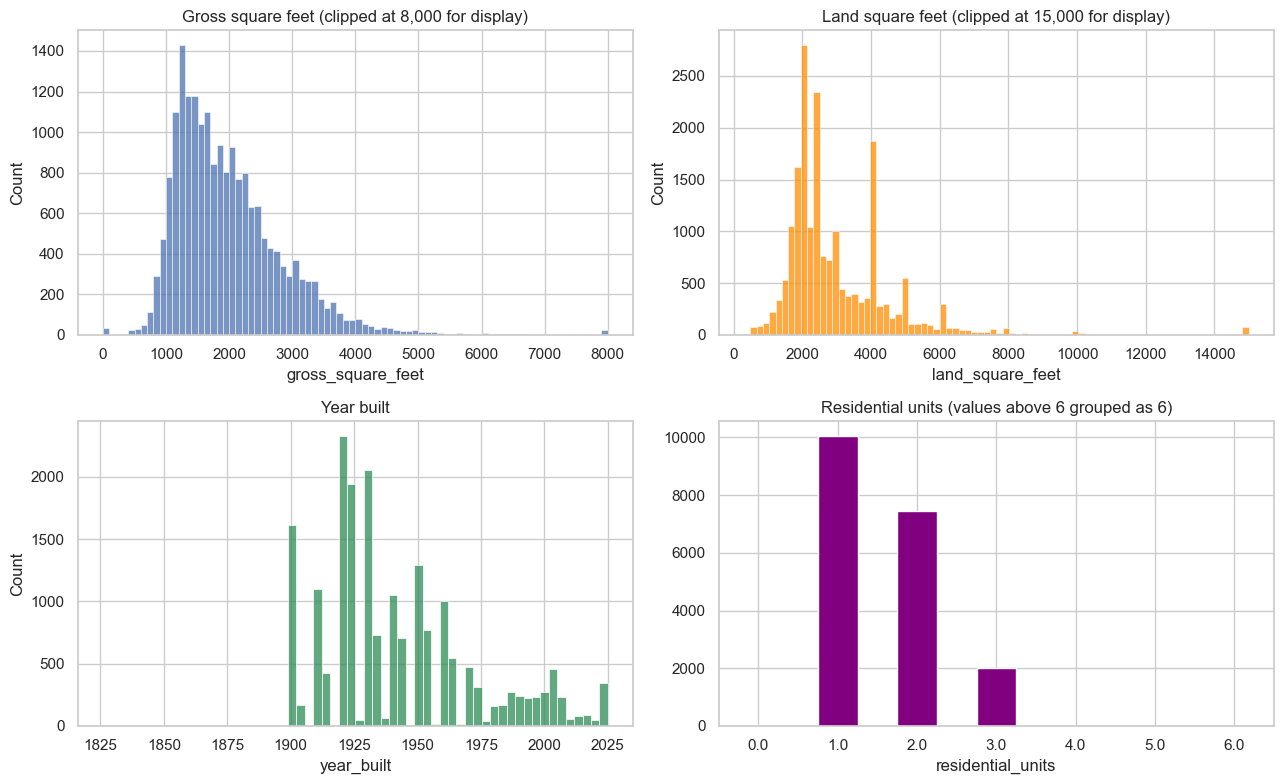

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

sns.histplot(df_res["gross_square_feet"].clip(upper=8_000), bins=80, ax=axes[0, 0])
axes[0, 0].set_title("Gross square feet (clipped at 8,000 for display)")

sns.histplot(df_res["land_square_feet"].clip(upper=15_000), bins=80, ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Land square feet (clipped at 15,000 for display)")

sns.histplot(df_res["year_built"], bins=60, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Year built")

df_res["residential_units"].clip(upper=6).value_counts().sort_index().plot.bar(ax=axes[1, 1], color="purple")
axes[1, 1].set_title("Residential units (values above 6 grouped as 6)")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Observations**
- Most homes are between about 1,300 and 2,400 sq ft of floor space on plots of 2,000–4,000 sq ft. Both have long right tails. Land size has sharp spikes at 2,000, 2,500 and 4,000 sq ft, which match the standard NYC lot sizes (20×100, 25×100 and 40×100 ft).
- `year_built` shows building waves: the 1920s–1930s and the post-war boom. There are also spikes at round years (1899, 1901, 1910, 1920, 1930…), which suggests that **many build years are estimates**, not exact records.
- Some homes have **more residential units than their category allows** (more than 3), and a few have **0 gross square feet**. These are data errors for Section 4.

### 3.6 Price by borough and home type (box plots)
Box plots compare the median and spread of price across groups and show outliers. Price is plotted on a log scale so that all boroughs are visible on one chart.

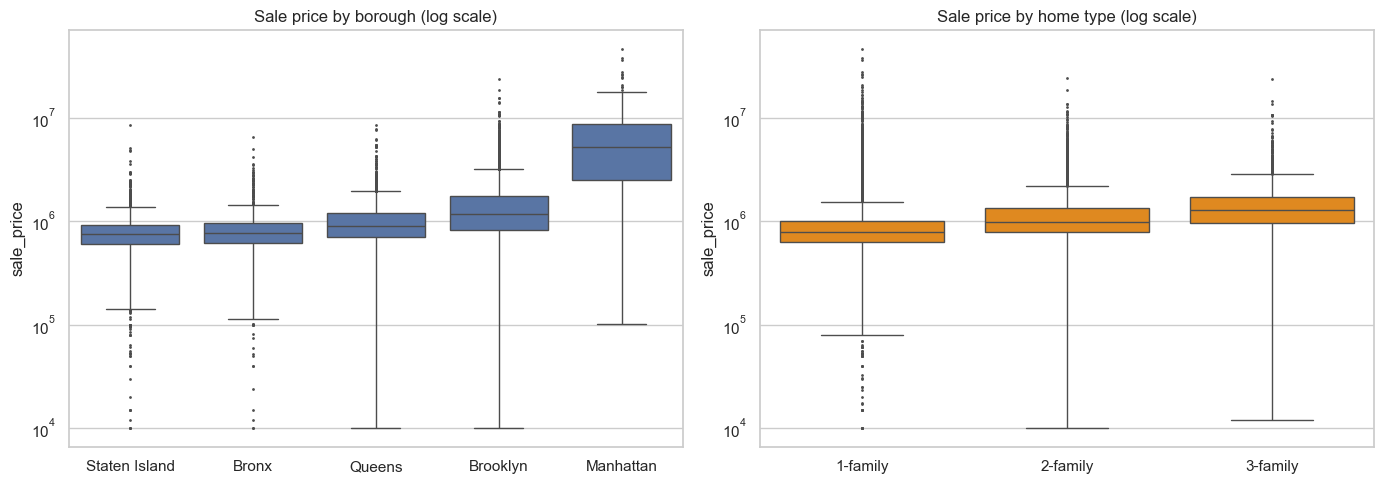

,count,mean,median,std
borough_name,,,,
Staten Island,3782,"800,318.91","745,000.00","371,564.61"
Bronx,2136,"806,913.25","760,000.00","388,347.91"
Queens,7918,"983,013.26","900,000.00","484,971.84"
Brooklyn,5572,"1,513,937.35","1,180,000.00","1,284,734.00"
Manhattan,237,"6,789,391.26","5,250,000.00","6,379,846.27"


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

borough_order = df_res.groupby("borough_name")["sale_price"].median().sort_values().index
sns.boxplot(data=df_res, x="borough_name", y="sale_price", order=borough_order,
            ax=axes[0], fliersize=1)
axes[0].set_yscale("log")
axes[0].set_title("Sale price by borough (log scale)")
axes[0].set_xlabel("")

sns.boxplot(data=df_res, x="home_type", y="sale_price", order=["1-family", "2-family", "3-family"],
            ax=axes[1], fliersize=1, color="darkorange")
axes[1].set_yscale("log")
axes[1].set_title("Sale price by home type (log scale)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

df_res.groupby("borough_name")["sale_price"].agg(["count", "mean", "median", "std"]).loc[borough_order]

**Observations**
- **Location is the strongest driver of price.** The median Manhattan house (about \$5.25M) costs about **7× the median in the Bronx or Staten Island** (about \$750k). Brooklyn (about \$1.18M) is clearly above Queens (about \$900k).
- The spread also differs a lot by borough (Manhattan's standard deviation is about \$6.4M vs about \$0.4M in the Bronx). The model must therefore know the location, and errors will naturally be larger in expensive areas.
- Median price rises with home type (about \$780k → \$990k → \$1.27M for 1 → 3 families), because more units mean a bigger building and rental income.
- Every group has outliers on both sides. The very low ones are suspicious (e.g. a Brooklyn house under \$100k) and are handled in Section 4.

### 3.7 Building size vs price (scatter plot)
A scatter plot shows whether a relationship is linear and how strong it is. Both axes are on a log scale because both variables are right-skewed.

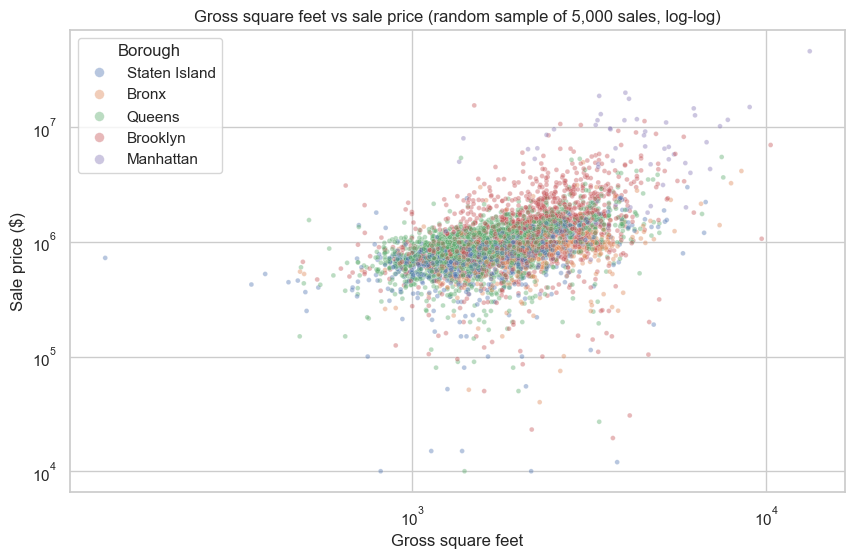

In [19]:
sample = df_res[df_res["gross_square_feet"] > 0].sample(5_000, random_state=RANDOM_STATE)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="gross_square_feet", y="sale_price",
                hue="borough_name", alpha=0.4, s=12, hue_order=borough_order)
plt.xscale("log")
plt.yscale("log")
plt.title("Gross square feet vs sale price (random sample of 5,000 sales, log-log)")
plt.xlabel("Gross square feet")
plt.ylabel("Sale price ($)")
plt.legend(title="Borough", markerscale=2)
plt.show()

**Observations:** there is a clear positive relationship (bigger homes sell for more), and on the log-log scale it is roughly linear. However, the cloud is wide: homes of the **same size** can differ in price by a factor of 3–5. At a given size, **Brooklyn and Manhattan homes sit higher** than Staten Island and Bronx homes, although the boroughs overlap heavily. Size alone explains only part of the price; **size and location together** are needed. This supports models that can capture interactions (tree ensembles) and the use of log-transformed size features.

### 3.8 Correlation matrix
Correlation measures how strongly each numeric feature moves with the price and with the other features:
- **Pearson** measures *linear* relationships. We compute it on log-transformed price and sizes because the raw variables are heavily skewed.
- **Spearman** uses ranks, so it captures any *monotonic* relationship and is robust to outliers.

High correlation between two *features* (multicollinearity) is also important: it makes linear-model coefficients unstable.

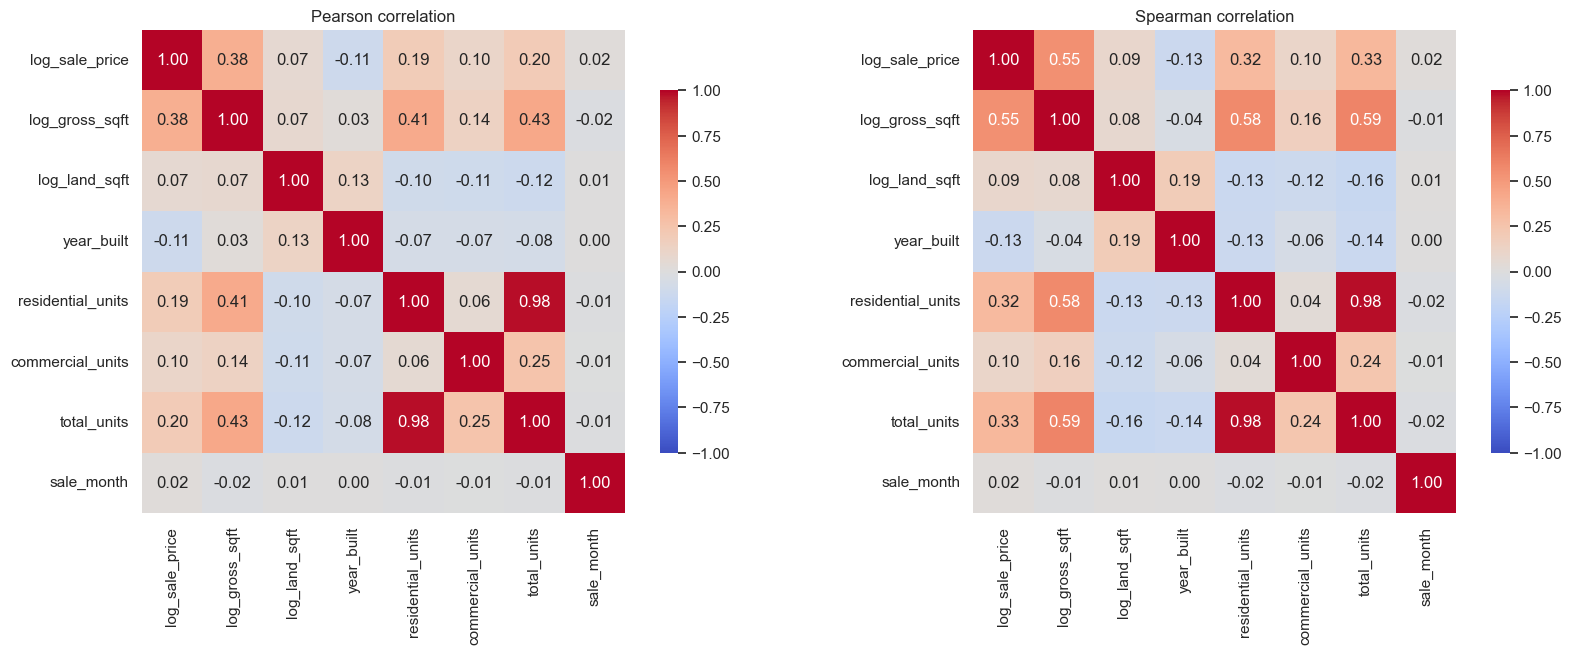

In [20]:
corr_df = pd.DataFrame({
    "log_sale_price":     np.log(df_res["sale_price"]),
    "log_gross_sqft":     np.log1p(df_res["gross_square_feet"]),
    "log_land_sqft":      np.log1p(df_res["land_square_feet"]),
    "year_built":         df_res["year_built"],
    "residential_units":  df_res["residential_units"],
    "commercial_units":   df_res["commercial_units"],
    "total_units":        df_res["total_units"],
    "sale_month":         df_res["sale_date"].dt.month,
})

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(corr_df.corr(method=method), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.75}, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation")
plt.tight_layout()
plt.show()

In [21]:
# Correlation of each feature with the (log) target, strongest first
corr_with_target = pd.DataFrame({
    "pearson":  corr_df.corr(method="pearson")["log_sale_price"],
    "spearman": corr_df.corr(method="spearman")["log_sale_price"],
}).drop("log_sale_price").sort_values("spearman", key=abs, ascending=False)
corr_with_target

,pearson,spearman
log_gross_sqft,0.38,0.55
total_units,0.20,0.33
residential_units,0.19,0.32
year_built,-0.11,-0.13
commercial_units,0.10,0.10
log_land_sqft,0.07,0.09
sale_month,0.02,0.02


**Observations**
- **Gross square feet** is the numeric feature most strongly correlated with price (Spearman about 0.55). Its Pearson correlation is lower (about 0.38) because of outliers and the non-linear, borough-dependent relationship seen in 3.7. This is why we report both measures.
- **Residential units** has a moderate positive correlation with price (about 0.3 Spearman), and it also correlates with gross square feet (more units mean a bigger building).
- **`residential_units` and `total_units` are almost perfectly correlated**, because commercial units are nearly always 0. Keeping both would add redundancy (multicollinearity) without new information, so only one is kept.
- `land_square_feet`, `year_built` and `sale_month` have **weak correlations** with price on their own. They may still help in combination with location (e.g. a large plot is worth much more in Brooklyn than in Staten Island), which tree-based models can capture.
- Overall, no single numeric feature explains price well. The box plots in 3.6 show that **location (borough/neighbourhood)** is the biggest factor, even though it does not appear in a numeric correlation matrix.

### 3.9 Sales over time
The 2025 data covers one calendar year. We check whether prices or sales volume change during the year, which tells us whether sale timing is a useful feature.

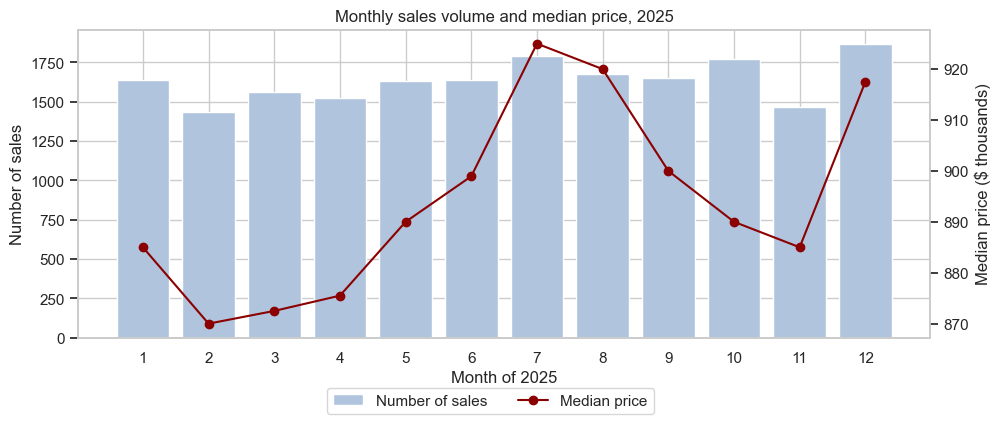

In [22]:
monthly = df_res.groupby(df_res["sale_date"].dt.month).agg(
    sales=("sale_price", "size"),
    median_price=("sale_price", "median"),
)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(monthly.index, monthly["sales"], color="lightsteelblue", label="Number of sales")
ax1.set_xlabel("Month of 2025")
ax1.set_ylabel("Number of sales")
ax1.set_xticks(range(1, 13))

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["median_price"] / 1e3, color="darkred", marker="o", label="Median price")
ax2.set_ylabel("Median price ($ thousands)")
ax2.grid(False)

fig.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.1))
plt.title("Monthly sales volume and median price, 2025")
plt.show()

**Observations:** sales volume is fairly steady (about 1,400–1,900 per month), and the median price moves only within a narrow band (about \$870k–\$925k), peaking in summer. The seasonal effect exists but is **small compared with location and size**. Sale month (or quarter) will be kept as a minor engineered feature.

### 3.10 Data-quality issues found during EDA
The EDA revealed several problems. We count them here; each one is handled with a justified method in **Section 4 — Data preparation**.

In [23]:
# Sales where several lots share the same block, date and price: usually one "package" deal
# recorded on several rows, each carrying the TOTAL price -> the price per row is overstated.
package_key = ["borough_name", "block", "sale_date", "sale_price"]
package_rows = df_res.duplicated(package_key, keep=False)

units_limit = df_res["home_type"].str[0].astype(int)   # 1, 2 or 3 units allowed
price_per_sqft = df_res["sale_price"] / df_res["gross_square_feet"].replace(0, np.nan)

issues = pd.Series({
    "Missing gross/land square feet":                     df_res["gross_square_feet"].isna().sum(),
    "Missing year built":                                 df_res["year_built"].isna().sum(),
    "Gross square feet recorded as 0":                    (df_res["gross_square_feet"] == 0).sum(),
    "More residential units than home type allows":       (df_res["residential_units"] > units_limit).sum(),
    "Building class changed between sale and today":      (df_res["building_class_at_present"]
                                                           != df_res["building_class_at_time_of_sale"]).sum(),
    "Rows belonging to multi-lot package sales":          package_rows.sum(),
    "Price per sq ft < $50 (implausibly cheap)":          (price_per_sqft < 50).sum(),
    "Price per sq ft > $3,000 (implausibly expensive)":   (price_per_sqft > 3_000).sum(),
    "Columns with a single value (tax class at sale)":    int(df_res["tax_class_at_time_of_sale"].nunique() == 1),
    "Columns 100% empty (easement, apartment number)":    int(df_res["easement"].isna().all())
                                                          + int(df_res["apartment_number"].isna().all()),
}, name="rows affected")
issues.to_frame()

,rows affected
Missing gross/land square feet,76
Missing year built,11
Gross square feet recorded as 0,36
More residential units than home type allows,59
Building class changed between sale and today,150
Rows belonging to multi-lot package sales,185
Price per sq ft < $50 (implausibly cheap),118
"Price per sq ft > $3,000 (implausibly expensive)",65
Columns with a single value (tax class at sale),1
"Columns 100% empty (easement, apartment number)",2


### 3.11 EDA summary
| Finding | Implication for the next steps |
|---|---|
| About half of 1–3 family records are non-market transfers (\$0 or token prices) | Restrict the model to market sales (≥ \$10k), and treat suspiciously cheap sales as outliers |
| Price is strongly right-skewed (skewness about 11) | Model `log(sale_price)`; evaluate in dollars with MAE/RMSE plus a relative metric (MAPE) |
| Location dominates price (Manhattan median about 7× the Bronx) | Location features (borough, neighbourhood/ZIP) must be included; high cardinality needs careful encoding |
| Size is the strongest numeric predictor, and the relationship differs by borough | Use log size features; prefer models that capture interactions (Random Forest, Gradient Boosting) and compare them with a linear baseline |
| `residential_units` ≈ `total_units`; `tax_class_at_time_of_sale` is constant; `easement`/`apartment_number` are empty | Drop redundant and empty columns |
| Missing sizes, zero sizes, impossible unit counts, package sales, extreme price per sq ft | Clean in Section 4 (imputation, correction or removal, each justified) |
| Very few Manhattan houses (about 240) | Report the error per borough; expect weaker accuracy for Manhattan |
| Small seasonal effect | Keep sale month/quarter as a minor feature |